# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [1]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.13.0.3" 2026-10-24
OpenJDK Runtime Environment (build 21.0.13.0.3+1-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.13.0.3+1-1-24.04.1-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.13.0.3


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [2]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [3]:
!java Hello.java

[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.13.0.3


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [4]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [5]:
!java TariffBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [6]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Overwriting TariffAfter.java


In [7]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [8]:
!apt-get update -qq
!apt-get install -y plantuml

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
plantuml is already the newest version (1:1.2020.2+ds-3ubuntu1.1).
0 upgraded, 0 newly installed, 0 to remove and 46 not upgraded.


In [9]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


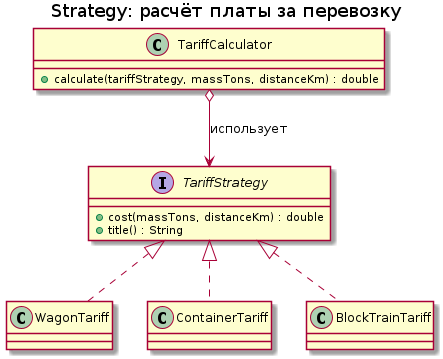

In [10]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   
   **Ответ:** В коде «до» пришлось бы изменить класс TariffBefore (добавить ветку else if в метод cost). В коде «после» нужно только создать новый класс, реализующий интерфейс TariffStrategy, и добавить его в каталог в методе main. Класс TariffCalculator и существующие стратегии менять не нужно.
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   
   **Ответ:** Метод legacyCost оставлен как эталон старого поведения. Он используется в характеризующих тестах, чтобы автоматически доказать, что новый код со стратегиями считает тарифы точно так же, как и старая запутанная логика (чтобы мы случайно не сломали то, что работало раньше).
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   
   **Ответ:** Если в каталоге не окажется нужного вида отправки, метод tariffCatalog.get(...) вернет null, и при попытке вызова calculate возникнет NullPointerException. Это следует обрабатывать явно: например, проверять наличие ключа через tariffCatalog.containsKey(...), либо использовать getOrDefault с дефолтной стратегией, либо выбрасывать понятное исключение (например, IllegalArgumentException).

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [11]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Overwriting FactoryBefore.java


In [12]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [25]:
%%writefile FactoryAfter.java
// Задача 1: Factory Method (Вариант 8: Пригородные перевозки - абонементы)
public class FactoryAfter {

    public static void main(String[] args) {

        // Вызывающий код (main) работает только с интерфейсами PassCreator и Pass
        // Никаких if/switch по типу абонемента здесь нет
        PassCreator[] creators = {
                new WeekendPassCreator(),
                new MonthlyPassCreator(),
                new StudentPassCreator(),
                new SchoolPassCreator() // 4-й тип добавлен новым классом
        };

        System.out.println("--- Информация об абонементах ---");
        for (PassCreator creator : creators) {
            Pass pass = creator.createPass();
            System.out.printf("%-25s | Цена: %6.2f руб.%n", pass.description(), pass.price());
        }

        System.out.println();
        System.out.println("--- Проверки ---");

        // 1. Описание не пустое и содержит цену (аналог грузоподъемности)
        check("Описание абонемента не пустое", !new WeekendPassCreator().createPass().description().isEmpty());
        check("Цена абонемента больше нуля", new WeekendPassCreator().createPass().price() > 0);

        // 2. Тип созданного объекта соответствует ожидаемому создателю
        check("WeekendPassCreator создает WeekendPass",
                new WeekendPassCreator().createPass() instanceof WeekendPass);
        check("MonthlyPassCreator создает MonthlyPass",
                new MonthlyPassCreator().createPass() instanceof MonthlyPass);
        check("StudentPassCreator создает StudentPass",
                new StudentPassCreator().createPass() instanceof StudentPass);

        // 3. Четвертый тип работает наравне с остальными
        Pass schoolPass = new SchoolPassCreator().createPass();
        check("Четвертый тип (SchoolPass) успешно создан", schoolPass instanceof SchoolPass);
        check("Четвертый тип имеет описание", !schoolPass.description().isEmpty());

        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            throw new AssertionError("Не пройдена проверка: " + checkName);
        }
    }
}

// --- участники паттерна Factory Method ---

/** Общий тип продукта: абонемент */
interface Pass {
    String description();
    double price();
}

/** Создатель с фабричным методом */
interface PassCreator {
    Pass createPass();
}

// Не менее трёх конкретных продуктов
class WeekendPass implements Pass {
    public String description() { return "Абонемент выходного дня"; }
    public double price() { return 500.0; }
}

class MonthlyPass implements Pass {
    public String description() { return "Единый месячный абонемент"; }
    public double price() { return 2500.0; }
}

class StudentPass implements Pass {
    public String description() { return "Студенческий абонемент"; }
    public double price() { return 1200.0; }
}

// Четвертый тип (добавлен новым классом)
class SchoolPass implements Pass {
    public String description() { return "Школьный абонемент"; }
    public double price() { return 800.0; }
}

// Конкретные создатели для каждого типа
class WeekendPassCreator implements PassCreator {
    public Pass createPass() { return new WeekendPass(); }
}

class MonthlyPassCreator implements PassCreator {
    public Pass createPass() { return new MonthlyPass(); }
}

class StudentPassCreator implements PassCreator {
    public Pass createPass() { return new StudentPass(); }
}

class SchoolPassCreator implements PassCreator {
    public Pass createPass() { return new SchoolPass(); }
}

Overwriting FactoryAfter.java


In [26]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Информация об абонементах ---
Абонемент выходного дня   | Цена: 500.00 руб.
Единый месячный абонемент | Цена: 2500.00 руб.
Студенческий абонемент    | Цена: 1200.00 руб.
Школьный абонемент        | Цена: 800.00 руб.

--- Проверки ---
[OK]   Описание абонемента не пустое
[OK]   Цена абонемента больше нуля
[OK]   WeekendPassCreator создает WeekendPass
[OK]   MonthlyPassCreator создает MonthlyPass
[OK]   StudentPassCreator создает StudentPass
[OK]   Четвертый тип (SchoolPass) успешно создан
[OK]   Четвертый тип имеет описание

Все проверки пройдены.


In [15]:
%%writefile factory.puml
@startuml
title Factory Method: создание абонемента (Вариант 8)

interface Pass {
  +description() : String
  +price() : double
}

interface PassCreator {
  +createPass() : Pass
}

class WeekendPass
class MonthlyPass
class StudentPass
class SchoolPass

class WeekendPassCreator
class MonthlyPassCreator
class StudentPassCreator
class SchoolPassCreator

PassCreator <|.. WeekendPassCreator
PassCreator <|.. MonthlyPassCreator
PassCreator <|.. StudentPassCreator
PassCreator <|.. SchoolPassCreator

WeekendPassCreator ..> WeekendPass : создаёт
MonthlyPassCreator ..> MonthlyPass : создаёт
StudentPassCreator ..> StudentPass : создаёт
SchoolPassCreator ..> SchoolPass : создаёт

Pass <|.. WeekendPass
Pass <|.. MonthlyPass
Pass <|.. StudentPass
Pass <|.. SchoolPass
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


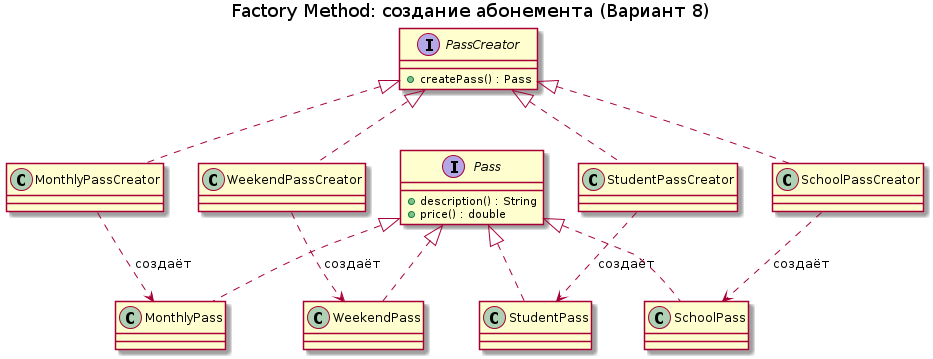

In [16]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): Создание через фабричный метод отличается от простого new тем, что вызывающий код не привязывается к конкретным классам продуктов. Клиент работает только с общими интерфейсами (Pass и PassCreator). Это позволяет добавлять новые типы (например, SchoolPass), не изменяя старый код в методе main. Фабрика излишня, если у нас всего 1-2 класса, которые никогда не будут расширяться, или если создание объекта очень простое – в таких случаях паттерн только добавит лишние классы и усложнит архитектуру.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [17]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [18]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [19]:
%%writefile ObserverAfter.java
import java.util.ArrayList;
import java.util.List;

// Задача 2: Observer (Вариант 8: Пригородные перевозки - изменение расписания)
public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        SuburbanStation station = new SuburbanStation("Минск-Пассажирский");

        // Создаем наблюдателей
        DisplayBoard board = new DisplayBoard();
        Journal journal = new Journal();
        Broadcast broadcast = new Broadcast();

        // Подписываем
        station.addListener(board);
        station.addListener(journal);
        station.addListener(broadcast);

        System.out.println("--- Событие 1: Изменение расписания (подписаны 3 наблюдателя) ---");
        station.scheduleChanged("Электричка 6001", "12:30");
        check("Журнал получил ровно одну запись", journal.getRecords().size() == 1);
        check("Все подписчики получили одно и то же событие",
                journal.getRecords().get(0).contains("6001") && board.getLastMessage().contains("6001"));

        System.out.println("\n--- Событие 2: Отписываем табло ---");
        station.removeListener(board);
        station.scheduleChanged("Электричка 6002", "12:45");

        check("После отписки табло не получило новое событие",
                !board.getLastMessage().contains("6002"));
        check("Журнал продолжает получать записи (их стало 2)",
                journal.getRecords().size() == 2);

        System.out.println("\n--- Событие 3: Добавление 4-го наблюдателя без правки класса SuburbanStation ---");
        MobileApp mobileApp = new MobileApp();
        station.addListener(mobileApp);
        station.scheduleChanged("Электричка 6003", "13:00");

        check("Новый наблюдатель MobileApp получил событие",
                mobileApp.getLastMessage().contains("6003"));
        check("Журнал накопил 3 записи", journal.getRecords().size() == 3);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println("\nВсе проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

// --- участники паттерна Observer ---

/** Наблюдатель */
interface ScheduleListener {
    void onScheduleChanged(String route, String newTime);
}

/** Субъект (Станция) */
class SuburbanStation {
    private final String name;
    private final List<ScheduleListener> listeners = new ArrayList<>();

    SuburbanStation(String name) {
        this.name = name;
    }

    void addListener(ScheduleListener listener) {
        listeners.add(listener);
    }

    void removeListener(ScheduleListener listener) {
        listeners.remove(listener);
    }

    void scheduleChanged(String route, String newTime) {
        System.out.println("[Станция " + name + "] Внимание! Изменено расписание: " + route + " -> " + newTime);
        for (ScheduleListener listener : listeners) {
            listener.onScheduleChanged(route, newTime);
        }
    }
}

// Конкретные наблюдатели
class DisplayBoard implements ScheduleListener {
    private String lastMessage = "";

    public void onScheduleChanged(String route, String newTime) {
        lastMessage = "Рейс " + route + " отправляется в " + newTime;
        System.out.println("  [Табло]     " + lastMessage);
    }
    String getLastMessage() { return lastMessage; }
}

class Journal implements ScheduleListener {
    private final List<String> records = new ArrayList<>();

    public void onScheduleChanged(String route, String newTime) {
        String record = "Зафиксировано изменение: " + route + " в " + newTime;
        records.add(record);
        System.out.println("  [Журнал]    " + record);
    }
    List<String> getRecords() { return records; }
}

class Broadcast implements ScheduleListener {
    public void onScheduleChanged(String route, String newTime) {
        System.out.println("  [Рассылка]  SMS/Email: Поезд " + route + " теперь в " + newTime);
    }
}

// 4-й наблюдатель
class MobileApp implements ScheduleListener {
    private String lastMessage = "";
    public void onScheduleChanged(String route, String newTime) {
        lastMessage = "Push: " + route + " в " + newTime;
        System.out.println("  [Моб. App]  " + lastMessage);
    }
    String getLastMessage() { return lastMessage; }
}

Overwriting ObserverAfter.java


In [20]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: Изменение расписания (подписаны 3 наблюдателя) ---
[Станция Минск-Пассажирский] Внимание! Изменено расписание: Электричка 6001 -> 12:30
  [Табло]     Рейс Электричка 6001 отправляется в 12:30
  [Журнал]    Зафиксировано изменение: Электричка 6001 в 12:30
  [Рассылка]  SMS/Email: Поезд Электричка 6001 теперь в 12:30
[OK]   Журнал получил ровно одну запись
[OK]   Все подписчики получили одно и то же событие

--- Событие 2: Отписываем табло ---
[Станция Минск-Пассажирский] Внимание! Изменено расписание: Электричка 6002 -> 12:45
  [Журнал]    Зафиксировано изменение: Электричка 6002 в 12:45
  [Рассылка]  SMS/Email: Поезд Электричка 6002 теперь в 12:45


In [21]:
%%writefile observer.puml
@startuml
title Observer: оповещение об изменении расписания (Вариант 8)

interface ScheduleListener {
  +onScheduleChanged(route, newTime) : void
}

class SuburbanStation {
  -listeners : List<ScheduleListener>
  +addListener(listener) : void
  +removeListener(listener) : void
  +scheduleChanged(route, newTime) : void
}

class DisplayBoard
class Journal
class Broadcast
class MobileApp

SuburbanStation o--> ScheduleListener : оповещает
ScheduleListener <|.. DisplayBoard
ScheduleListener <|.. Journal
ScheduleListener <|.. Broadcast
ScheduleListener <|.. MobileApp
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


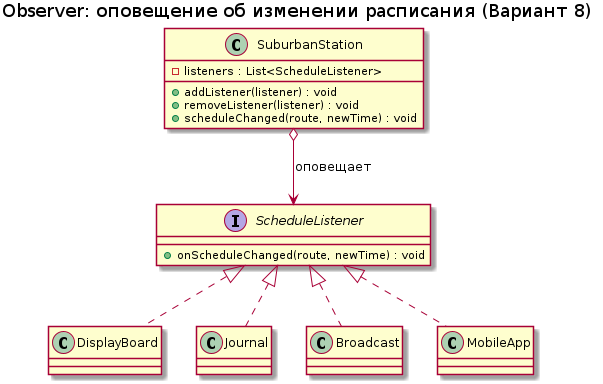

In [22]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка):

**Какую связанность снял Observer:** Источник события (Станция) больше не зависит от конкретных получателей (Табло, Журнала и т.д.). Мы можем добавлять новых наблюдателей (например, MobileApp), не изменяя код класса SuburbanStation.

**Порядок уведомлений:** Событие получают подписчики в том порядке, в котором они были добавлены в список (сначала Табло, затем Журнал, затем Рассылка).

**Новые проблемы:**
1) Ошибка в одном подписчике — если один подписчик упадет с ошибкой (выбросит исключение), остальные могут не получить событие (нужно оборачивать вызов в try-catch).
2) Забытая отписка — если объект-наблюдатель больше не нужен, но не отписался (не вызвал removeListener), он останется в памяти (утечка памяти), так как субъект хранит на него ссылку.

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy |Громоздкий метод с множеством if/else, нарушающий принцип открытости/закрытости.|Новая стратегия (класс) для расчета.|Увеличение количества классов.|Тарификация по зонам (расчет стоимости проезда).|
| Factory Method |Жесткая привязка к конкретным классам при создании объектов через new.|Новый класс-создатель и новый продукт (тип абонемента).|Необходимость создавать отдельный класс-создатель для каждого продукта.|Создание абонементов (выходного дня, студенческий и т.д.).|
| Observer |Жесткая связь источника событий со всеми получателями.|Новый класс-наблюдатель (подписчик).|Накладные расходы на обход списка подписчиков, риск утечек памяти.|Оповещение пассажиров об изменении расписания.|

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?

   **Ответ:** Нарушается принцип открытости/закрытости (Open/Closed). Условный оператор требует изменения класса при добавлении новых типов. Strategy восстанавливает принцип, вынося каждый алгоритм в отдельный класс. Factory Method выносит создание объектов в подклассы-создатели. Observer позволяет добавлять новых подписчиков без изменения кода источника событий.

2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?

   **Ответ:** Статический фабричный метод — это просто вспомогательный метод внутри класса, возвращающий экземпляр (он не использует наследование и полиморфизм). Abstract Factory предназначен для создания целых семейств взаимосвязанных объектов. Factory Method использует наследование: у нас есть интерфейс создателя, а конкретные подклассы решают, какой именно продукт инстанцировать.

3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
  
   **Ответ:** Структурно они похожи, но назначение разное. Strategy используется для выбора алгоритма (клиент сам передает нужную стратегию в контекст). State используется для изменения поведения объекта при изменении его внутреннего состояния (переходы между состояниями происходят автоматически внутри объекта, а не по воле клиента).

4. Почему Observer может привести к утечке памяти и как этого избежать?

   **Ответ:** Субъект хранит жесткие ссылки на наблюдателей. Если наблюдатель больше не нужен, но не отписался (забыли вызвать removeListener), сборщик мусора не сможет его удалить, пока жив субъект. Чтобы избежать утечки, используют слабые ссылки (WeakReference) на наблюдателей или строго следят за своевременной отпиской.

5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?

   **Ответ:** Введение паттерна вредно, когда он решает проблему, которой не существует. Например, если в программе всего два типа сущностей и они никогда не будут расширяться, создание сложной иерархии классов с фабриками — это лишнее. Преждевременное усложнение — это добавление абстракций и паттернов «на будущее», когда в них нет реальной необходимости, что делает код менее понятным.

### 5.3 Три вывода по работе в целом

1. Паттерны проектирования — это эффективные инструменты для соблюдения принципов SOLID, которые позволяют изолировать изменения и делать архитектуру гибкой.
2. Замена условных операторов полиморфизмом (через Strategy и Factory Method) позволяет добавлять новую функциональность, не модифицируя уже протестированный и работающий код.
3. Любая гибкость требует компромисса: за слабую связанность и расширяемость приходится платить увеличением количества классов и усложнением структуры проекта.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [Х] Раздел 1 выполнен, версия Java не ниже 11
- [Х] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [Х] Отвечены вопросы к образцу (п. 2.5)
- [Х] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [Х] Четвёртый тип вагона добавлен новым классом
- [Х] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [Х] Четвёртый наблюдатель добавлен без правки класса `Station`
- [Х] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [Х] Заполнена итоговая таблица (п. 5.1)
- [Х] Отвечены пять контрольных вопросов и сформулированы три вывода
- [Х] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [Х] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [27]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Змушко Вероника Павловна"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 8  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Змушко Вероника Павловна, группа ГИ-41, вариант 8 |
| Дата и время отчёта (UTC) | 2026-11-15 10:59 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 7 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 6 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |